#Simple Linear Regression on Placement Dataset


# Import Libraries

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## Data Loading

Here, the dataset is loaded into a pandas DataFrame named `data`.

In [47]:
data = pd.read_csv("/content/placement.csv")
data

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0
...,...,...,...
995,8.87,44.0,1
996,9.12,65.0,1
997,4.89,34.0,0
998,8.62,46.0,1


## Initial Data Exploration and Cleaning

This section involves a preliminary look at the data, checking for missing values, inspecting column names and data types, and handling duplicate entries.

In [48]:
data.head()

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0


In [49]:
data.shape

(1000, 3)

#### Check for Missing Values

Calculate the percentage of missing values for each column to understand data completeness.

In [50]:
data.isna().sum()/100

,0
cgpa,0.0
placement_exam_marks,0.0
placed,0.0


In [51]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   cgpa                  1000 non-null   float64
 1   placement_exam_marks  1000 non-null   float64
 2   placed                1000 non-null   int64  
dtypes: float64(2), int64(1)
memory usage: 23.6 KB


## Check for Duplicate Values


In [52]:
data.duplicated().sum()

np.int64(19)

## Drop Duplicate Values

In [54]:
data = data.drop_duplicates()

In [55]:
data.shape

(981, 3)

In [56]:
data.columns

Index(['cgpa', 'placement_exam_marks', 'placed'], dtype='object')

## Individual Correlations with 'placed'

In [57]:
# Loop through all columns in `data` to print the correlation between 'placed' and each feature.
for col_name in data.columns:
  # Ensure 'placed' is not correlated with itself and avoid unnecessary computations if col_name is already 'placed'.
  if col_name != 'placed':
    print(f"Correlation between placed and {col_name} =\n{np.corrcoef(data['placed'], data[col_name])}\n")

Correlation between placed and cgpa =
[[1.         0.02676687]
 [0.02676687 1.        ]]

Correlation between placed and placement_exam_marks =
[[ 1.         -0.02341476]
 [-0.02341476  1.        ]]



## Correlation Matrix

Let's calculate the correlation matrix to examine the linear relationships between the variables in the dataset.

In [58]:
correlation_matrix = data.corr()
display(correlation_matrix)

,cgpa,placement_exam_marks,placed
cgpa,1.000000,-0.031832,0.026767
placement_exam_marks,-0.031832,1.000000,-0.023415
placed,0.026767,-0.023415,1.000000


## Visualize Correlation Matrix


In [62]:
import seaborn as sns

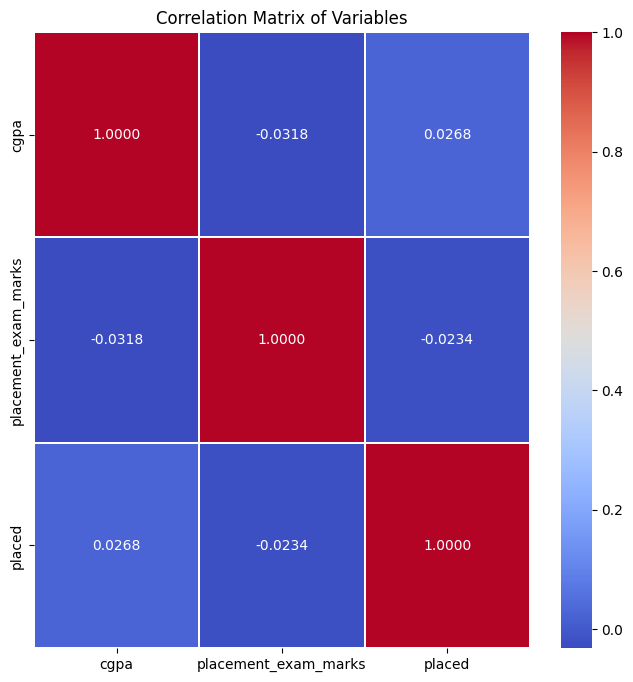

In [71]:
plt.figure(figsize=(8, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".4f", linewidths=.10)
plt.title('Correlation Matrix of Variables')
plt.show()

## Split Features & Target

In [72]:
X = data.loc[:,['cgpa', 'placement_exam_marks']]
Y = data.loc[:,['placed']]

In [73]:
X.head()

,cgpa,placement_exam_marks
0,7.19,26.0
1,7.46,38.0
2,7.54,40.0
3,6.42,8.0
4,7.23,17.0


In [74]:
Y.head()

,placed
0,1
1,1
2,1
3,1
4,0


In [75]:
from sklearn.linear_model import LinearRegression
regressor = LinearRegression()
regressor.fit(X,Y)

LinearRegression()

## Make Predictions

In [76]:
y_pred = regressor.predict(X)
y_pred

array([[0.49884299],
       [0.49747351],
       [0.49798332],
       [0.49320031],
       [0.50498381],
       [0.50292838],
       [0.49712814],
       [0.48971519],
       [0.47617521],
       [0.47062777],
       [0.49692656],
       [0.49294541],
       [0.49186557],
       [0.46700098],
       [0.50401989],
       [0.49988808],
       [0.48904543],
       [0.5089997 ],
       [0.49277167],
       [0.50635569],
       [0.47593887],
       [0.49978384],
       [0.47329486],
       [0.48363219],
       [0.49185629],
       [0.46081853],
       [0.51492036],
       [0.47315348],
       [0.50380663],
       [0.49097804],
       [0.51042251],
       [0.49815945],
       [0.48067995],
       [0.47801048],
       [0.52909296],
       [0.51319862],
       [0.49755918],
       [0.53668444],
       [0.48951121],
       [0.50540556],
       [0.45108596],
       [0.48144707],
       [0.47805001],
       [0.49098283],
       [0.49632418],
       [0.50256684],
       [0.50763711],
       [0.481

In [79]:
from sklearn.metrics import mean_squared_error, r2_score
r2 = r2_score(Y, y_pred)
print(f"R-squared: {r2 : .4f}")

mse = mean_squared_error(Y, y_pred)
print(f"Mean Squared Error: {mse : .4f}")

R-squared:  0.0012
Mean Squared Error:  0.2496


In [80]:
print("Intercept :",regressor.intercept_)
print("Coefficients :", regressor.coef_)

Intercept : [0.36252778]
Coefficients : [[ 0.02108742 -0.00058859]]
